In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
print(sys.path[0])

/home/benjamin-rodriguez/Desktop/PredictionMarkets


/home/benjamin-rodriguez/Desktop/PredictionMarkets/analysis/microstructure.py:39: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(sql, conn)


<Axes: >

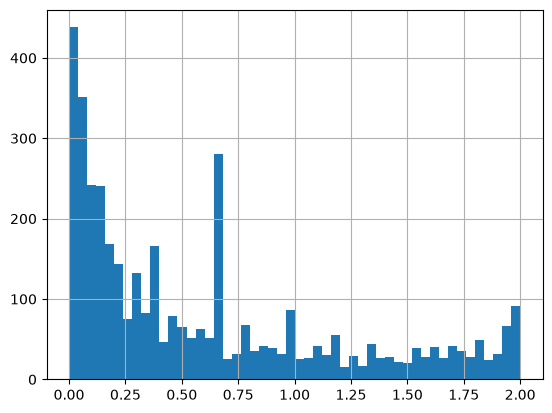

In [2]:
from analysis.microstructure import relative_spread, effective_spread_cost, get_current_spreads
import numpy as np

df = get_current_spreads()
df["relative_spread"] = relative_spread(df["best_bid"], df["best_ask"])
df["effective_cost"] = effective_spread_cost(df["best_bid"], df["best_ask"])

df["relative_spread"].hist(bins=50)

In [3]:
df[df["relative_spread"] >= .66][["market_id", "best_bid", "best_ask", "mid_price", "relative_spread"]]

,market_id,best_bid,best_ask,mid_price,relative_spread
5,1005732,0.002,0.006,0.0040,1.000000
7,1006907,0.003,0.208,0.1055,1.943128
8,1006908,0.040,0.570,0.3050,1.737705
9,1006909,0.040,0.140,0.0900,1.111111
10,1006910,0.063,0.714,0.3885,1.675676
...,...,...,...,...,...
4272,996328,0.005,0.012,0.0085,0.823529
4273,996329,0.003,0.007,0.0050,0.800000
4275,996331,0.004,0.009,0.0065,0.769231
4278,996334,0.001,0.005,0.0030,1.333333


In [4]:
print(df["relative_spread"].isna().sum(), "NaN values")
print(np.isinf(df["relative_spread"]).sum(), "inf values")

# drop them before computing stats
clean = df[np.isfinite(df["relative_spread"])]
clean["relative_spread"].describe()

367 NaN values
0 inf values


count    3916.000000
mean        0.602901
std         0.592118
min         0.001001
25%         0.117647
50%         0.400000
75%         0.950820
max         2.000000
Name: relative_spread, dtype: float64

In [5]:
frac_above_10pct = (clean["relative_spread"] > 0.1).mean()
print(f"{frac_above_10pct:.1%} of markets have relative spread above 10%")

77.0% of markets have relative spread above 10%


## Plot Volume vs Spread log-log scale

In [6]:
# only active relevant markets. 

clean = df[
    (df["best_bid"] > 0) &
    (df["best_ask"] < 1) &
    (df["volume_24h"] > 0)
].copy()
clean["relative_spread"].describe()

count    2235.000000
mean        0.391529
std         0.453132
min         0.001003
25%         0.068966
50%         0.193548
75%         0.620690
max         1.978300
Name: relative_spread, dtype: float64

In [7]:
import matplotlib.pyplot as plt

log_volume = np.log10(clean["volume_24h"])
log_spread = np.log10(clean["relative_spread"])

slope, intercept = np.polyfit(log_volume, log_spread, deg=1)
print(f"slope (power-law exponent) = {slope:.3f}")
print(f"intercept = {intercept:.3f}")

slope (power-law exponent) = -0.149
intercept = -0.381


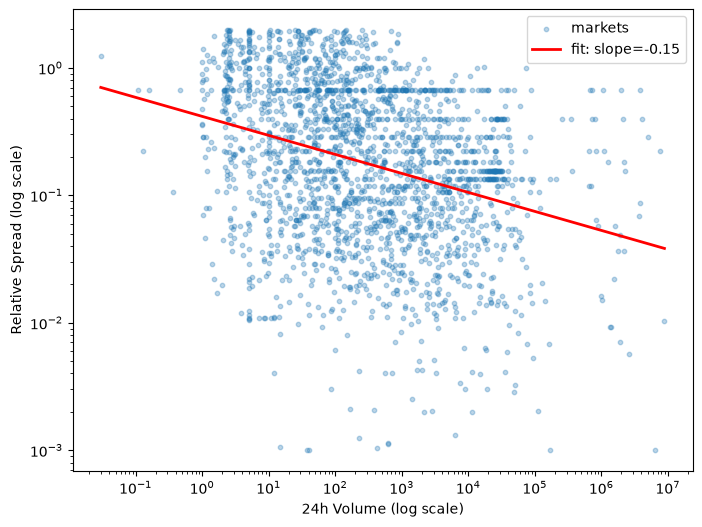

In [8]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(clean["volume_24h"], clean["relative_spread"], alpha=0.3, s=10, label="markets")

x_line = np.linspace(log_volume.min(), log_volume.max(), 100)
y_line = slope * x_line + intercept
ax.plot(10**x_line, 10**y_line, color="red", linewidth=2, label=f"fit: slope={slope:.2f}")

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("24h Volume (log scale)")
ax.set_ylabel("Relative Spread (log scale)")
ax.legend()
plt.show()

In [9]:
correlation = np.corrcoef(log_volume, log_spread)[0, 1]
print(f"correlation (in log-log space) = {correlation:.3f}")

correlation (in log-log space) = -0.312


# Plot High Volume Markets

In [10]:
ids = clean.loc[clean["volume_24h"] >= 10**5, "market_id"].head(3).tolist()

ids

['1652697', '1652706', '2034723']

/home/benjamin-rodriguez/Desktop/PredictionMarkets/db/queries.py:189: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(sql, conn, params=(market_ids,))


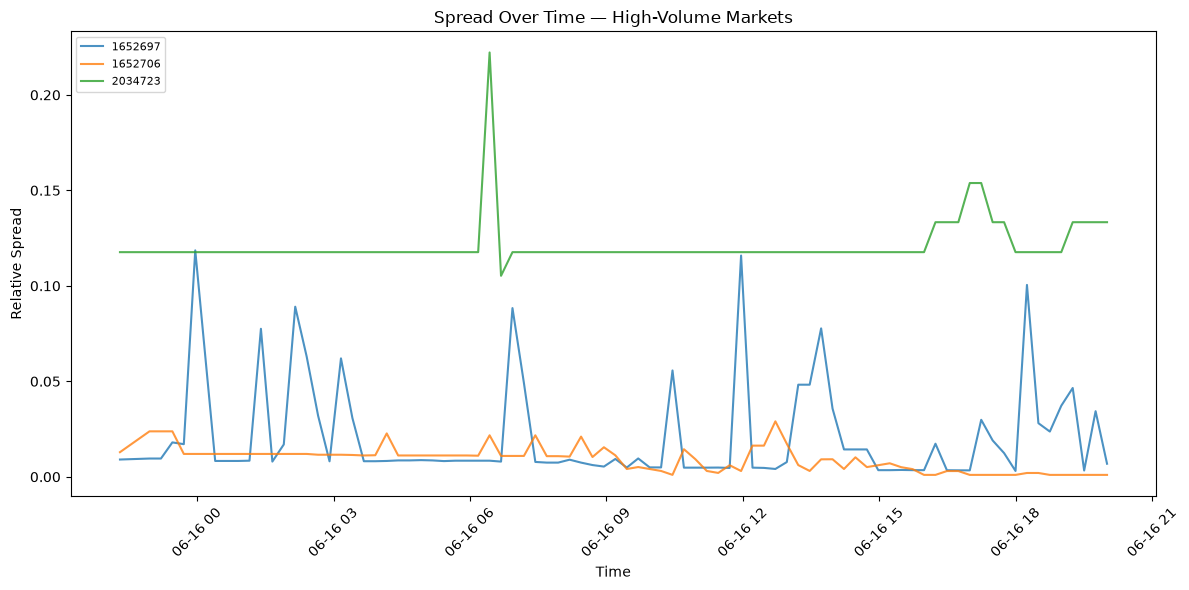

In [11]:
from db.queries import get_snapshot_history

history = get_snapshot_history(ids)

history["relative_spread"] = relative_spread(history["best_bid"], history["best_ask"])

fig, ax = plt.subplots(figsize=(12, 6))

for market_id, group in history.groupby("market_id"):
    ax.plot(group["snapshot_at"], group["relative_spread"], label=market_id, alpha=0.8)

ax.set_xlabel("Time")
ax.set_ylabel("Relative Spread")
ax.set_title("Spread Over Time — High-Volume Markets")
ax.legend(loc="upper left", fontsize=8)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [12]:
flat_market = history[history["market_id"] == "2034723"]
flat_market[["snapshot_at", "best_bid", "best_ask", "mid_price", "spread", "volume_24h"]]

,snapshot_at,best_bid,best_ask,mid_price,spread,volume_24h
170,2026-06-15 22:18:18.785130+00:00,0.008,0.009,0.0085,0.001,115526.294957
171,2026-06-15 22:57:15.961294+00:00,0.008,0.009,0.0085,0.001,118430.528858
172,2026-06-15 23:12:22.076631+00:00,0.008,0.009,0.0085,0.001,116342.898858
173,2026-06-15 23:27:27.045221+00:00,0.008,0.009,0.0085,0.001,116474.218537
174,2026-06-15 23:42:32.220955+00:00,0.008,0.009,0.0085,0.001,116474.218537
...,...,...,...,...,...,...
250,2026-06-16 19:00:02.616918+00:00,0.008,0.009,0.0085,0.001,173906.705474
251,2026-06-16 19:15:07.691919+00:00,0.007,0.008,0.0075,0.001,175188.524676
252,2026-06-16 19:30:13.156376+00:00,0.007,0.008,0.0075,0.001,173938.524676
253,2026-06-16 19:45:18.405448+00:00,0.007,0.008,0.0075,0.001,172735.291036


## Tag Markets

In [18]:
from analysis.microstructure import liquidity_tier
import pandas as pd

clean["liquidity_tier"] = clean["relative_spread"].apply(liquidity_tier)

In [19]:
clean["liquidity_tier"] = pd.cut(
    clean["relative_spread"],
    bins=[0, 0.02, 0.05, 0.10, float("inf")],
    labels=["tight", "medium", "wide", "untradeable"]
)

In [20]:
clean["liquidity_tier"].value_counts()

liquidity_tier
untradeable    1502
wide            309
medium          251
tight           173
Name: count, dtype: int64